# Before Rutherford: Why the Plum-Pudding Atom Had to Go

> *Before the Rutherford model of the atom, which best describes the understanding of the atom?*

The question is about history, so start with the timeline. Then do what physicists
actually did: **compute what each model predicts** and compare with the experiment.

| part | tool | result |
|---|---|---|
| 1 | timeline | which options are even possible |
| 2 | Gauss's law (SymPy) | field inside Thomson's positive sphere |
| 3 | an impulse integral + maximize (calculus) | the largest deflection a plum-pudding atom can give |
| 4 | a random walk (statistics, Monte Carlo) | many small kicks never add up to 90° |
| 5 | Rutherford's nucleus | back-scattering becomes rare, but observable |
| 6 | writing | explain it in your own words |

Module: [`dgs/thomson_vs_rutherford.py`](../dgs/thomson_vs_rutherford.py). MATLAB twin:
[`learn/matlab/thomson_vs_rutherford.m`](../learn/matlab/thomson_vs_rutherford.m).
All numbers are **order-of-magnitude estimates** with stated assumptions: 7.7 MeV
alphas, a 0.4 µm gold foil, and a gold atomic radius of 1.44 Å.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()
from dgs.thomson_vs_rutherford import (
    thomson_field_symbolic, thomson_deflection_symbolic, theta_max_thomson, theta_max_electron,
    collisions_in_foil, theta_rms_multiple, log10_prob_beyond_multiple, rutherford_prob_beyond,
    mc_random_walk_rms, TIMELINE, GOLD, ALPHA, FOIL_T,
)

# 1. The timeline answers the question

In [2]:
for year, who, what in TIMELINE:
    print(f"{year}  {who:17s} {what}")

1803  Dalton            atomic theory of chemistry: matter is made of atoms
1897  J. J. Thomson     discovers the electron (cathode rays, e/m)
1904  J. J. Thomson     plum-pudding model: electrons in a sphere of positive charge
1909  Geiger & Marsden  a few alphas bounce back from gold foil
1911  Rutherford        nuclear model: tiny dense positive nucleus
1913  Bohr              quantized orbits around Rutherford's nucleus


- **"Bohr model was most popular before Rutherford."** Impossible: Bohr (1913) built his
  model *on top of* Rutherford's nucleus (1911).
- **"Matter universally accepted as continuous."** No. Chemists had used atoms since
  Dalton (1803), and Thomson had already found the electron (1897).
- **Thomson's plum pudding**: positive charge smeared over the whole atom, with
  electrons embedded like raisins. This was the model Rutherford overturned.

So the answer is **Thomson's plum-pudding model**. The rest of the notebook shows
*why* it had to go.

# 2. The field inside a plum pudding (Gauss's law)

For charge $Q$ spread uniformly through a sphere of radius $R$, a Gaussian sphere of
radius $r < R$ encloses $Q\,r^3/R^3$. So the field grows **linearly** from the center
and is never very strong anywhere:

<IPython.core.display.Math object>

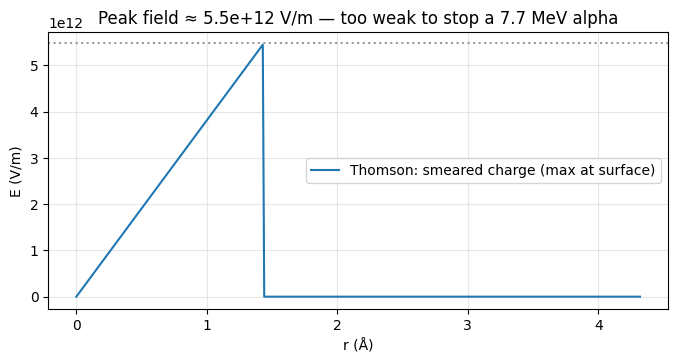

In [3]:
display(Math(r"E(r < R) = " + sp.latex(thomson_field_symbolic())))
k_ = 8.988e9; e_ = 1.602e-19; Q = GOLD["Z"]*e_; R = GOLD["R_atom"]
r = np.linspace(0, 3*R, 400)
E_thomson = np.where(r < R, k_*Q*r/R**3, 0)            # screened outside (neutral atom)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(r/1e-10, E_thomson, label="Thomson: smeared charge (max at surface)")
ax.axhline(k_*Q/R**2, color="0.6", ls=":")
ax.set(xlabel="r (Å)", ylabel="E (V/m)", title=f"Peak field ≈ {k_*Q/R**2:.1e} V/m — too weak to stop a 7.7 MeV alpha")
ax.legend(); ax.grid(alpha=0.3); plt.show()

# 3. The largest kick a plum pudding can give (calculus)

An alpha moving at speed $v$ along a straight line at distance $b$ from the center feels a
sideways force $F_\perp = kqQ\,b/R^3$ while inside the sphere (along a chord of length
$2\sqrt{R^2-b^2}$). The sideways momentum is the integral of force over time,
$\Delta p_\perp = \int F_\perp\,dt$ with $dt = dx/v$. Divide by $p = mv$, use
$mv^2 = 2K$, and maximize over $b$:

In [4]:
theta, b_star, theta_max = thomson_deflection_symbolic()
display(Math(r"\theta(b) = " + sp.latex(theta)))
display(Math(r"\frac{d\theta}{db} = 0 \;\Rightarrow\; b^* = " + sp.latex(b_star)
             + r",\qquad \theta_\max = " + sp.latex(theta_max)))
print(f"gold, 7.7 MeV alpha:   θ_max (positive sphere) = {theta_max_thomson():.3e} rad = {np.degrees(theta_max_thomson())*3600:.0f} arcsec")
print(f"one electron at rest:  θ_max = arcsin(m_e/m_α) = {theta_max_electron():.3e} rad")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

gold, 7.7 MeV alpha:   θ_max (positive sphere) = 1.026e-04 rad = 21 arcsec
one electron at rest:  θ_max = arcsin(m_e/m_α) = 1.371e-04 rad


Both are about $10^{-4}$ rad, roughly 0.006°. A single plum-pudding atom can barely
nudge the alpha.

# 4. Many small kicks: a random walk that goes nowhere fast

The foil is about $N = t\,n^{1/3}$ atoms thick. Give Thomson every advantage and assume
*every* atom delivers the maximum kick, in a random direction. Random kicks add like a
random walk, $\theta_\text{rms} = \sqrt N\,\theta_1$ (checked by Monte Carlo below), and
the chance of ending beyond an angle $T$ is a Gaussian tail:

$$P(\theta > T) = e^{-T^2/\theta_\text{rms}^2}\quad\Rightarrow\quad \log_{10}P = -\frac{T^2}{\theta_\text{rms}^2\ln 10}$$

In [5]:
print(f"random walk check: Monte Carlo {mc_random_walk_rms(1e-4, 400):.5f} vs √N·θ = {theta_rms_multiple(1e-4, 400):.5f}")
th1 = max(theta_max_thomson(), theta_max_electron()); N = collisions_in_foil()
th_rms = theta_rms_multiple(th1, N)
print(f"\ncollisions crossing a {FOIL_T*1e6:.1f} µm foil: N ≈ {N:.0f}")
print(f"θ_rms ≈ {th_rms:.4f} rad = {np.degrees(th_rms):.2f}°")
for T_deg in (1, 2, 5, 10, 90):
    print(f"  Thomson   P(θ > {T_deg:3d}°) = 10^({log10_prob_beyond_multiple(np.radians(T_deg), th_rms):,.0f})")

random walk check: Monte Carlo 0.00201 vs √N·θ = 0.00200

collisions crossing a 0.4 µm foil: N ≈ 1557
θ_rms ≈ 0.0054 rad = 0.31°
  Thomson   P(θ >   1°) = 10^(-5)
  Thomson   P(θ >   2°) = 10^(-18)
  Thomson   P(θ >   5°) = 10^(-113)
  Thomson   P(θ >  10°) = 10^(-452)
  Thomson   P(θ >  90°) = 10^(-36,614)


Even with every assumption tilted in Thomson's favor, the chance of bouncing back is
about $10^{-36{,}000}$. That's not "rare". It means *never*, not once in the age of the
universe.

# 5. Rutherford's nucleus: one close encounter is enough

Put all the positive charge in a tiny nucleus and the field near it becomes enormous. A
single close pass can turn the alpha around. The fraction scattered beyond $T$ is the
target area $\pi b(T)^2$ per nucleus, times the number of nuclei per unit area, $nt$:

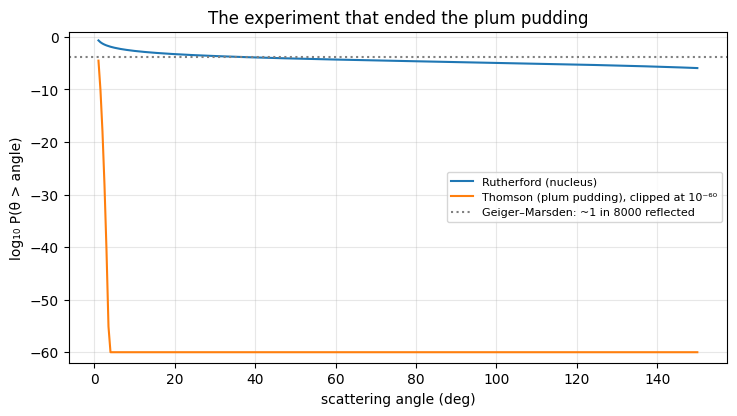

P(θ > 90°): Rutherford 1.6e-05   vs   Thomson 10^(-36,614)


In [6]:
Ts = np.radians(np.linspace(1, 150, 300))
P_R = rutherford_prob_beyond(Ts)
log_T = np.array([log10_prob_beyond_multiple(T, th_rms) for T in Ts])
fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.plot(np.degrees(Ts), np.log10(P_R), label="Rutherford (nucleus)")
ax.plot(np.degrees(Ts), np.maximum(log_T, -60), label="Thomson (plum pudding), clipped at 10⁻⁶⁰")
ax.axhline(np.log10(1/8000), color="0.5", ls=":", label="Geiger–Marsden: ~1 in 8000 reflected")
ax.set(xlabel="scattering angle (deg)", ylabel="log₁₀ P(θ > angle)", ylim=(-62, 1),
       title="The experiment that ended the plum pudding")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()
print(f"P(θ > 90°): Rutherford {rutherford_prob_beyond(np.pi/2):.1e}   vs   Thomson 10^({log10_prob_beyond_multiple(np.pi/2, th_rms):,.0f})")

Rutherford's estimate lands within about an order of magnitude of what Geiger and
Marsden saw. Their foils, energies and geometry differed from these assumptions, so
only the order of magnitude is meaningful. Thomson's prediction is off by tens of
thousands of orders of magnitude. In Rutherford's own words, it was as if a shell
fired at tissue paper had come back and hit him.

# 6. Writing: say it in your own words

A strong short answer has three sentences:

1. **Claim:** which model came before Rutherford.
2. **Evidence:** what the gold-foil experiment observed.
3. **Reasoning:** why that observation rules the model out (use one number from §4 or §5).

*Template (fill in, don't copy):* "Before 1911, physicists described the atom with
______. In the gold-foil experiment, ______. This model could not explain that because ______."

## Exercises
1. Redo §4 with a foil 10× thicker. Does Thomson's back-scatter probability become measurable?
2. Find the alpha energy at which Rutherford's $b_{90}$ equals the nuclear radius (~7 fm for gold). What happens above it?
3. Replace the Gaussian-tail formula with a direct Monte Carlo for $N = 1557$. Why can't Monte Carlo test the 90° prediction?
4. In MATLAB, plot $\theta(b)$ from §3 and mark its maximum at $b = R/\sqrt2$.